# 01 — Análise exploratória (Pessoa A, T04)

**Objetivo:** entender as avaliações da Olist antes de montar a base de conhecimento do RAG e
justificar, com dados, as decisões da preparação (T05), do índice (T06) e dos temas (T08).

Cada seção segue o mesmo formato: **pergunta → gráfico → o que encontramos → decisão no pipeline.**
O resumo das decisões está em [Conclusões](#Conclusões), no fim.

**Como rodar:** gere a base antes (`python -m src.prepare`) e depois rode todas as células.
Os números vêm de `data/silver/` e `data/gold/`, os mesmos arquivos que alimentam o RAG, então batem
com o README. As figuras principais são salvas em `docs/eda/`.

In [1]:
import json
import re
import sys
import unicodedata
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
DATA = ROOT / "data"
FIG = ROOT / "docs" / "eda"
FIG.mkdir(parents=True, exist_ok=True)

# Paleta: cinza para o contexto, azul-petróleo para o destaque, vermelho para o negativo
CINZA, DESTAQUE, NEGATIVO, POSITIVO = "#9aa5b1", "#0e6b74", "#b23a48", "#2f7d4f"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "font.size": 10.5,
})
pd.set_option("display.width", 140)


def salvar(fig, nome):
    fig.savefig(FIG / f"{nome}.png")


def pct(x, casas=0):
    return f"{x * 100:.{casas}f}%".replace(".", ",")


def num(x):
    return f"{x:,.0f}".replace(",", ".")


def dec(x, casas=1):
    return f"{x:.{casas}f}".replace(".", ",")

In [2]:
reviews = pd.read_parquet(DATA / "silver" / "reviews.parquet")            # todas as avaliações
completo = pd.read_parquet(DATA / "gold" / "reviews_completo.parquet")    # avaliações com conteúdo
qualidade = json.loads((DATA / "gold" / "_qualidade.json").read_text(encoding="utf-8"))
reviews["negativa"] = reviews["review_score"] <= 2
print(f"{num(len(reviews))} avaliações | {num(len(completo))} com conteúdo | "
      f"{num(completo['no_indice'].sum())} no índice do RAG")

99.224 avaliações | 41.951 com conteúdo | 34.912 no índice do RAG


## 1. Quanto da base serve para o RAG?

O RAG só consegue recuperar o que tem texto. Este funil mostra o caminho de todas as avaliações até os
documentos que entram no índice, com as regras da camada gold (`src/medallion/gold.py`).

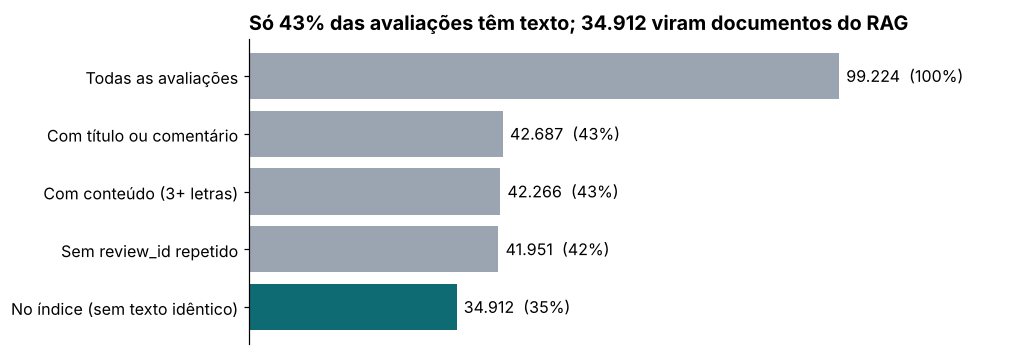

,etapa,n,pct
0,Todas as avaliações,99224,1.000000
1,Com título ou comentário,42687,0.430208
2,Com conteúdo (3+ letras),42266,0.425965
3,Sem review_id repetido,41951,0.422791
4,No índice (sem texto idêntico),34912,0.351850


In [3]:
etapas = [
    ("Todas as avaliações", qualidade["reviews_silver"]),
    ("Com título ou comentário", qualidade["reviews_silver"] - qualidade["removidas_sem_texto"]),
    ("Com conteúdo (3+ letras)", qualidade["reviews_silver"] - qualidade["removidas_sem_texto"] - qualidade["removidas_sem_conteudo"]),
    ("Sem review_id repetido", qualidade["documentos_reviews_completo"]),
    ("No índice (sem texto idêntico)", qualidade["documentos_indice"]),
]
funil = pd.DataFrame(etapas, columns=["etapa", "n"])
funil["pct"] = funil["n"] / funil["n"].iloc[0]

fig, ax = plt.subplots(figsize=(9, 3.6))
cores = [CINZA] * (len(funil) - 1) + [DESTAQUE]
ax.barh(funil["etapa"][::-1], funil["n"][::-1], color=cores[::-1])
for i, (n, p) in enumerate(zip(funil["n"][::-1], funil["pct"][::-1])):
    ax.text(n + 1200, i, f"{num(n)}  ({pct(p)})", va="center")
ax.set_xlim(0, funil["n"].max() * 1.3)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.set_title(f"Só {pct(funil['pct'].iloc[1])} das avaliações têm texto; "
             f"{num(funil['n'].iloc[-1])} viram documentos do RAG")
salvar(fig, "01_funil")
plt.show()
funil

**O que encontramos.** Mais da metade das avaliações é só a nota, sem nenhum texto. Das que têm
texto, poucas são vazias de conteúdo ("." ou "ok"), e o maior corte depois disso é de textos
idênticos (seção 4).

**Decisão.** Só avaliações com texto viram documento do RAG. As notas sem texto continuam na silver
e servem para estatísticas, mas não para citar evidências.

## 2. Quem escreve comentário?

Se clientes insatisfeitos escrevem mais, a base do RAG não representa todos os clientes.

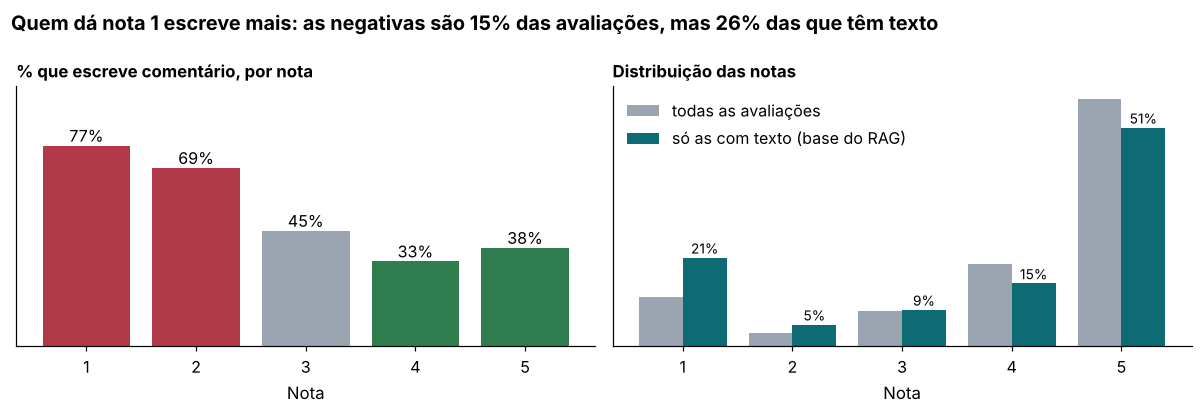

,n,com_texto
review_score,,
1,11424,77.3
2,3151,68.7
3,8179,44.5
4,19142,32.8
5,57328,38.0


In [4]:
por_nota = reviews.groupby("review_score").agg(n=("review_id", "size"), com_texto=("tem_texto", "mean"))
dist = pd.DataFrame({
    "todas": reviews["review_score"].value_counts(normalize=True),
    "com texto": reviews.loc[reviews["tem_texto"], "review_score"].value_counts(normalize=True),
}).sort_index()
neg_todas = reviews["negativa"].mean()
neg_texto = reviews.loc[reviews["tem_texto"], "negativa"].mean()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
cores = [NEGATIVO, NEGATIVO, CINZA, POSITIVO, POSITIVO]
a1.bar(por_nota.index.astype(str), por_nota["com_texto"], color=cores)
for x, v in zip(por_nota.index.astype(str), por_nota["com_texto"]):
    a1.text(x, v + 0.015, pct(v), ha="center")
a1.set_ylim(0, 1)
a1.set_yticks([])
a1.set_xlabel("Nota")
a1.set_title("% que escreve comentário, por nota", fontsize=11)

x = np.arange(5)
a2.bar(x - 0.2, dist["todas"], 0.4, color=CINZA, label="todas as avaliações")
a2.bar(x + 0.2, dist["com texto"], 0.4, color=DESTAQUE, label="só as com texto (base do RAG)")
a2.set_xticks(x, [str(i) for i in range(1, 6)])
a2.set_xlabel("Nota")
a2.set_yticks([])
for xi, v in zip(x, dist["com texto"]):
    a2.text(xi + 0.2, v + 0.01, pct(v), ha="center", fontsize=9)
a2.legend(frameon=False, loc="upper left")
a2.set_title("Distribuição das notas", fontsize=11)

fig.suptitle(f"Quem dá nota 1 escreve mais: as negativas são {pct(neg_todas)} das avaliações, "
             f"mas {pct(neg_texto)} das que têm texto", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
salvar(fig, "02_quem_escreve")
plt.show()
por_nota.assign(com_texto=lambda d: (d["com_texto"] * 100).round(1))

**O que encontramos.** A chance de escrever cai à medida que a nota sobe: quem está insatisfeito
explica o motivo, e quem está satisfeito costuma só dar a nota. Por isso, a proporção de negativas
quase dobra quando olhamos só as avaliações com texto.

**Decisão.** O RAG responde sobre *o que os clientes escrevem*, que é uma amostra mais crítica do que
a base inteira. Respostas sobre proporções ("os clientes estão satisfeitos?") devem usar a nota de
todas as avaliações, e não só os documentos recuperados. Vale citar essa limitação no README e na
apresentação.

## 3. Qual o tamanho dos textos?

O tamanho define se cada avaliação precisa ser dividida em pedaços (chunks) antes de virar embedding.

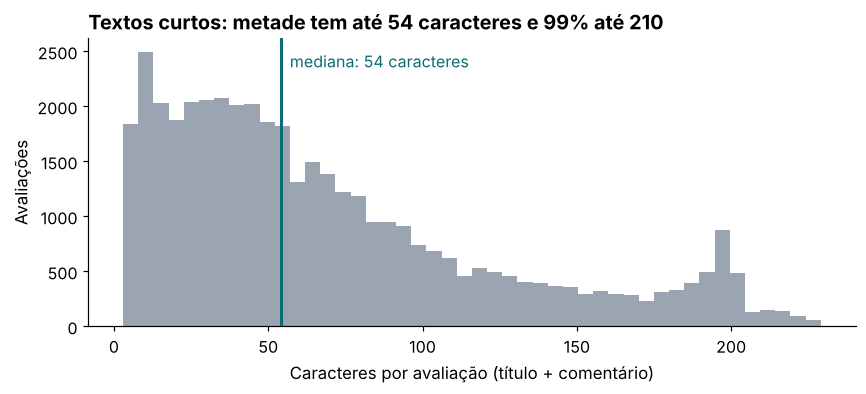

Comentários com exatamente 200 caracteres: 659 (com 199: 318; com 201: 22); maior comentário: 208


count    41951.0
mean        70.0
std         55.0
min          3.0
10%         12.0
50%         54.0
90%        162.0
99%        210.0
max        229.0
Name: tamanho_texto, dtype: float64

In [5]:
tam = completo["tamanho_texto"]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(tam, bins=46, color=CINZA)
ax.axvline(tam.median(), color=DESTAQUE, lw=2)
ax.text(tam.median() + 3, ax.get_ylim()[1] * 0.9, f"mediana: {tam.median():.0f} caracteres", color=DESTAQUE)
ax.set_xlabel("Caracteres por avaliação (título + comentário)")
ax.set_ylabel("Avaliações")
ax.set_title(f"Textos curtos: metade tem até {tam.median():.0f} caracteres e 99% até {tam.quantile(.99):.0f}")
salvar(fig, "03_tamanho")
plt.show()
msg = reviews["review_comment_message"].dropna().str.len()
print(f"Comentários com exatamente 200 caracteres: {num((msg == 200).sum())} "
      f"(com 199: {num((msg == 199).sum())}; com 201: {num((msg == 201).sum())}); maior comentário: {msg.max()}")
tam.describe(percentiles=[.1, .5, .9, .99]).round(0)

**O que encontramos.** As avaliações são curtas, do tamanho de uma ou duas frases. O pico perto de
200 caracteres não é natural: centenas de comentários têm exatamente 200 caracteres e quase nenhum
passa disso, o que indica um limite de tamanho no formulário de avaliação. Alguns textos longos
podem ter sido cortados no meio.

**Decisão.** Cada avaliação vira um único documento (1 review = 1 chunk), sem divisão. Isso também
mantém cada citação [R#] ligada a uma avaliação inteira. Textos com menos de 3 letras ("." , "10",
emojis soltos) são removidos porque não carregam informação.

## 4. Há textos repetidos?

Se o mesmo texto aparece centenas de vezes, ele pode ocupar todas as posições do top-k da busca.

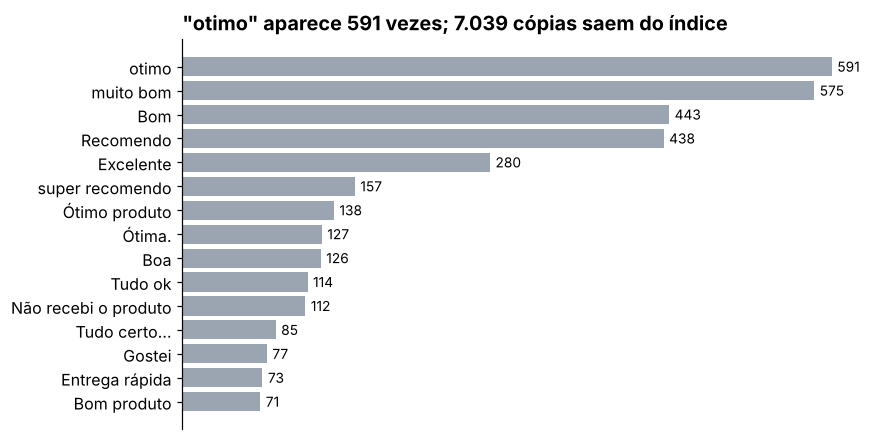

In [6]:
repetidos = (completo[completo["no_indice"]]
             .nlargest(15, "qtd_textos_identicos")[["texto", "qtd_textos_identicos"]])
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(repetidos["texto"][::-1], repetidos["qtd_textos_identicos"][::-1], color=CINZA)
for i, v in enumerate(repetidos["qtd_textos_identicos"][::-1]):
    ax.text(v + 5, i, num(v), va="center", fontsize=9)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.set_title(f"\"{repetidos['texto'].iloc[0]}\" aparece {num(repetidos['qtd_textos_identicos'].iloc[0])} vezes; "
             f"{num(qualidade['removidas_texto_identico'])} cópias saem do índice")
salvar(fig, "04_repetidos")
plt.show()

**O que encontramos.** Os textos mais repetidos são elogios genéricos de uma ou duas palavras.
Ignorando maiúsculas, acentos e pontuação, milhares de avaliações são cópias exatas de outras.

**Decisão.** O índice guarda uma cópia de cada texto (a avaliação mais antiga), para que a busca
devolva evidências variadas. As contagens reais continuam em `reviews_completo.parquet`
(`qtd_textos_identicos`), usado nas respostas agregadas.

## 5. Como a base se distribui no tempo?

Define que períodos o RAG consegue responder com evidência suficiente.

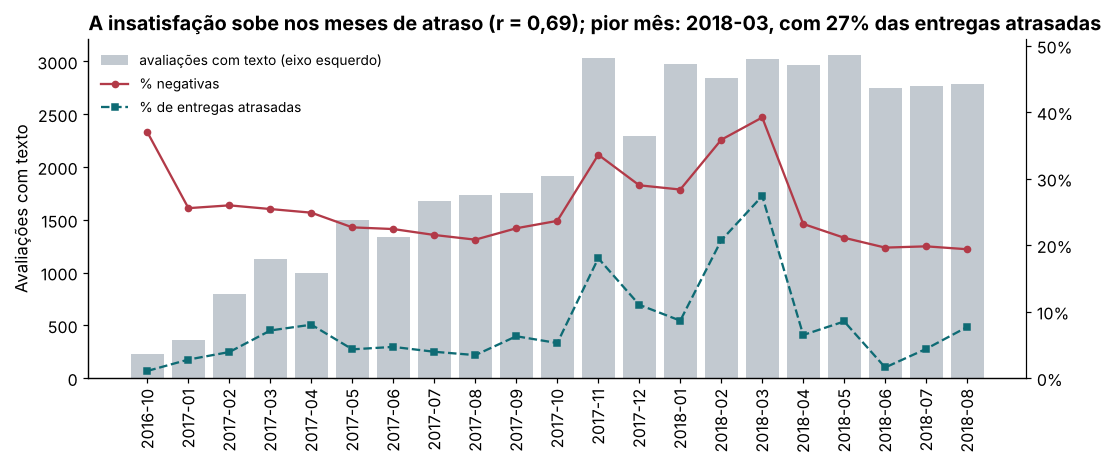

Meses com menos de 100 avaliações (fora do gráfico): 2016-09, 2016-12, 2018-09, 2018-10 (14 avaliações no total)


data_compra,2016-10,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,...,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
n,230,360,793,1125,997,1500,1334,1682,1739,1753,...,3034,2297,2980,2846,3026,2963,3057,2747,2771,2787
negativas,37.0,25.6,26.0,25.4,24.9,22.7,22.4,21.5,20.8,22.5,...,33.6,29.0,28.4,35.8,39.2,23.2,21.1,19.6,19.8,19.4
atrasadas,1.1,2.8,3.9,7.2,8.0,4.3,4.7,4.0,3.5,6.3,...,18.0,11.0,8.6,20.7,27.4,6.5,8.5,1.6,4.4,7.7


In [7]:
mensal = (completo.groupby("data_compra")
          .agg(n=("review_id", "size"), negativas=("sentimento", lambda s: (s == "negativo").mean())))
mensal["atrasadas"] = (completo[completo["entregue"]].groupby("data_compra")["dias_atraso"]
                       .apply(lambda s: (s > 0).mean()))
mensal_ok = mensal[mensal["n"] >= 100]
pior = mensal_ok["negativas"].idxmax()
r_mes = mensal_ok["negativas"].corr(mensal_ok["atrasadas"])

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(mensal_ok.index, mensal_ok["n"], color=CINZA, alpha=0.6, label="avaliações com texto (eixo esquerdo)")
ax.set_ylabel("Avaliações com texto")
ax.tick_params(axis="x", rotation=90)
ax2 = ax.twinx()
ax2.plot(mensal_ok.index, mensal_ok["negativas"], color=NEGATIVO, marker="o", ms=4, label="% negativas")
ax2.plot(mensal_ok.index, mensal_ok["atrasadas"], color=DESTAQUE, marker="s", ms=4, ls="--",
         label="% de entregas atrasadas")
ax2.yaxis.set_major_formatter(lambda v, _: pct(v))
ax2.spines["right"].set_visible(True)
ax2.set_ylim(0, max(mensal_ok["negativas"].max(), mensal_ok["atrasadas"].max()) * 1.3)
linhas = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax2.legend(linhas, [l.get_label() for l in linhas], frameon=False, loc="upper left", fontsize=9)
ax.set_title(f"A insatisfação sobe nos meses de atraso (r = {dec(r_mes, 2)}); "
             f"pior mês: {pior}, com {pct(mensal_ok.loc[pior, 'atrasadas'])} das entregas atrasadas")
salvar(fig, "05_tempo")
plt.show()
fora = mensal[mensal["n"] < 100]
print(f"Meses com menos de 100 avaliações (fora do gráfico): {', '.join(fora.index)} "
      f"({num(fora['n'].sum())} avaliações no total)")
mensal_ok.assign(negativas=lambda d: (d["negativas"] * 100).round(1),
                 atrasadas=lambda d: (d["atrasadas"] * 100).round(1)).T

**O que encontramos.** Quase todas as compras com avaliação vão de 2017 a agosto de 2018. A
insatisfação não é constante: ela sobe exatamente nos meses em que as entregas atrasam. Em novembro
de 2017 o volume salta de ~1,9 mil para ~3 mil avaliações, o atraso passa de ~5% para 18% e as
negativas sobem de ~24% para ~34%. Em fevereiro e março de 2018 o atraso chega a 21% e 27%, e as
negativas, a 36% e 39%. Quando o atraso volta a cair, a insatisfação volta para ~20%. É a seção 6
vista no tempo: o atraso explica os picos de insatisfação, não uma piora dos produtos.

**Decisão.** Os filtros de período (`ano_mes`) fazem sentido para 2017–2018. Perguntas sobre 2016 ou
sobre o fim de 2018 têm pouquíssima evidência, e o RAG deve dizer isso em vez de generalizar.

## 6. O atraso explica a insatisfação?

`dias_atraso` = data real de entrega − data prometida (positivo = atrasou). Só pedidos entregues.

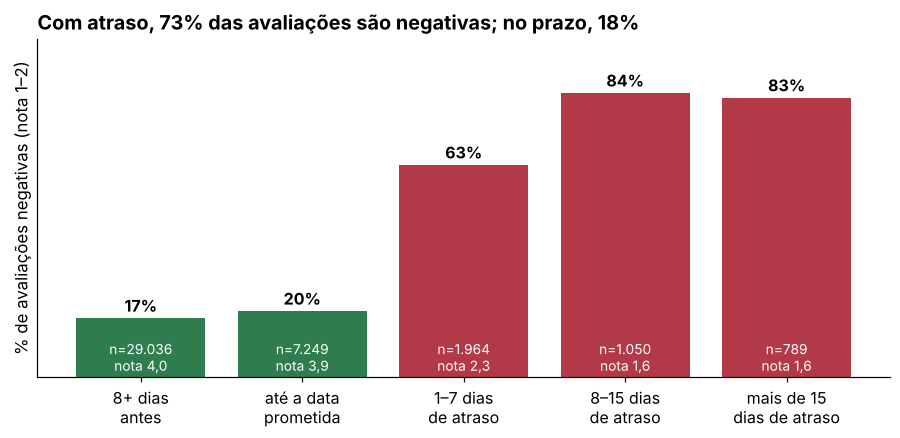

72% das entregas chegam 8+ dias antes da data prometida.
Pedidos não entregues: 1.863 avaliações, 85% negativas.


,n,negativas,nota_media
faixa,,,
8+ dias\nantes,29036,17.5,4.03
até a data\nprometida,7249,19.5,3.89
1–7 dias\nde atraso,1964,62.7,2.27
8–15 dias\nde atraso,1050,83.9,1.55
mais de 15\ndias de atraso,789,82.5,1.58


In [8]:
entregues = completo[completo["entregue"]].copy()
faixas = [-10_000, -8, 0, 7, 15, 10_000]
rotulos = ["8+ dias\nantes", "até a data\nprometida", "1–7 dias\nde atraso", "8–15 dias\nde atraso", "mais de 15\ndias de atraso"]
entregues["faixa"] = pd.cut(entregues["dias_atraso"], bins=faixas, labels=rotulos)
atraso = (entregues.groupby("faixa", observed=True)
          .agg(n=("review_id", "size"),
               negativas=("sentimento", lambda s: (s == "negativo").mean()),
               nota_media=("review_score", "mean")))
nao_entregues = completo[~completo["entregue"]]
neg_nao_entregue = (nao_entregues["sentimento"] == "negativo").mean()
no_prazo = entregues["dias_atraso"] <= 0
neg_prazo = (entregues.loc[no_prazo, "sentimento"] == "negativo").mean()
neg_atraso = (entregues.loc[~no_prazo, "sentimento"] == "negativo").mean()
adiantados = (entregues["dias_atraso"] <= -8).mean()

fig, ax = plt.subplots(figsize=(10, 4))
cores = [POSITIVO, POSITIVO, NEGATIVO, NEGATIVO, NEGATIVO]
barras = ax.bar(atraso.index.astype(str), atraso["negativas"], color=cores)
for b, (v, n, nota) in zip(barras, atraso[["negativas", "n", "nota_media"]].values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.02, pct(v), ha="center", fontweight="bold")
    ax.text(b.get_x() + b.get_width() / 2, 0.02, f"n={num(n)}\nnota {dec(nota)}",
            ha="center", color="white", fontsize=9)
ax.set_ylim(0, 1)
ax.set_yticks([])
ax.set_ylabel("% de avaliações negativas (nota 1–2)")
ax.set_title(f"Com atraso, {pct(neg_atraso)} das avaliações são negativas; no prazo, {pct(neg_prazo)}")
salvar(fig, "06_atraso")
plt.show()
print(f"{pct(adiantados)} das entregas chegam 8+ dias antes da data prometida.")
print(f"Pedidos não entregues: {num(len(nao_entregues))} avaliações, {pct(neg_nao_entregue)} negativas.")
atraso.assign(negativas=lambda d: (d["negativas"] * 100).round(1), nota_media=lambda d: d["nota_media"].round(2))

**O que encontramos.** É o achado mais forte da base. Enquanto a entrega chega até a data prometida,
a maioria das avaliações é positiva. Bastam alguns dias de atraso para a maioria virar negativa, e
com mais de uma semana de atraso a nota média cai para perto de 1,5. Pedidos não entregues são os
mais negativos de todos.

Outro detalhe: a data prometida é folgada. A maior parte das entregas chega com mais de uma semana de
antecedência, então o cliente compara a entrega com uma expectativa que normalmente é superada.

**Decisão.** `dias_atraso` e `atrasou` entram como metadados filtráveis no índice (T06), para perguntas
como "o que reclamam os clientes com entrega atrasada?". O tema `atraso_entrega` e o tema
`nao_recebido` (T08) são separados porque têm intensidades de insatisfação diferentes.

## 7. A experiência varia por estado?

Cada ponto é um estado (UF do cliente); o tamanho é o número de avaliações com texto.

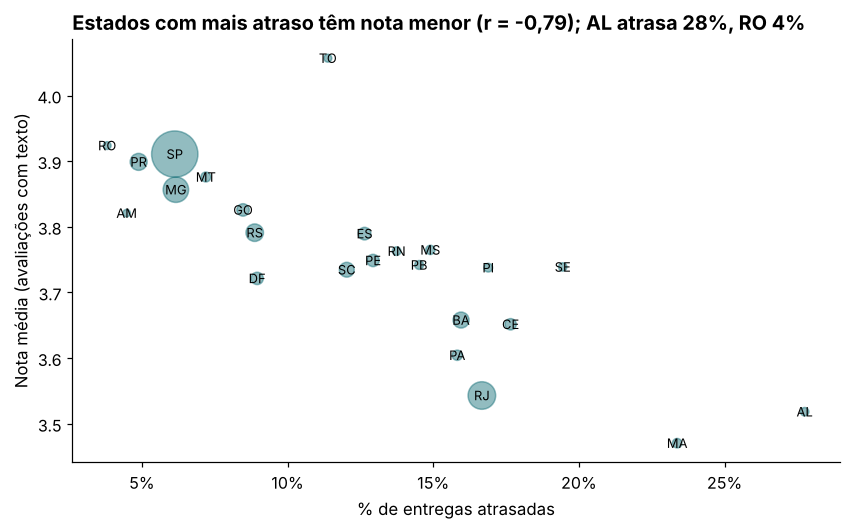

,n,atraso,nota_media
estado,,,
AL,191,27.7,3.52
MA,338,23.4,3.47
SE,180,19.4,3.74
CE,640,17.7,3.65
PI,225,16.9,3.74
RJ,5513,16.7,3.54
BA,1617,16.0,3.66
PA,455,15.8,3.60
MS,302,14.9,3.76


In [9]:
uf = (entregues.groupby("estado")
      .agg(n=("review_id", "size"),
           atraso=("dias_atraso", lambda s: (s > 0).mean()),
           nota_media=("review_score", "mean")))
uf = uf[uf["n"] >= 50]
r = np.corrcoef(uf["atraso"], uf["nota_media"])[0, 1]
pior_uf = uf["atraso"].idxmax()
melhor_uf = uf["atraso"].idxmin()

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(uf["atraso"], uf["nota_media"], s=uf["n"] / uf["n"].max() * 900 + 20,
           color=DESTAQUE, alpha=0.45, edgecolor=DESTAQUE)
for sigla, linha in uf.iterrows():
    ax.annotate(sigla, (linha["atraso"], linha["nota_media"]), ha="center", va="center", fontsize=8.5)
ax.xaxis.set_major_formatter(lambda v, _: pct(v))
ax.set_xlabel("% de entregas atrasadas")
ax.set_ylabel("Nota média (avaliações com texto)")
ax.set_title(f"Estados com mais atraso têm nota menor (r = {dec(r, 2)}); "
             f"{pior_uf} atrasa {pct(uf.loc[pior_uf, 'atraso'])}, {melhor_uf} {pct(uf.loc[melhor_uf, 'atraso'])}")
salvar(fig, "07_estados")
plt.show()
uf.sort_values("atraso", ascending=False).assign(
    atraso=lambda d: (d["atraso"] * 100).round(1), nota_media=lambda d: d["nota_media"].round(2)).head(10)

**O que encontramos.** Os estados não têm a mesma experiência: onde a entrega atrasa mais, a nota é
menor, o que reforça a seção 6. SP concentra a maior parte das avaliações.

**Decisão.** `estado` entra como metadado filtrável, para perguntas regionais ("reclamações de
clientes do RJ"). Em estados com poucas avaliações, o RAG terá pouca evidência e deve sinalizar isso.

## 8. Quais categorias geram mais reclamação?

Categoria principal do pedido (item de maior preço). Só as 15 categorias com mais avaliações com texto.

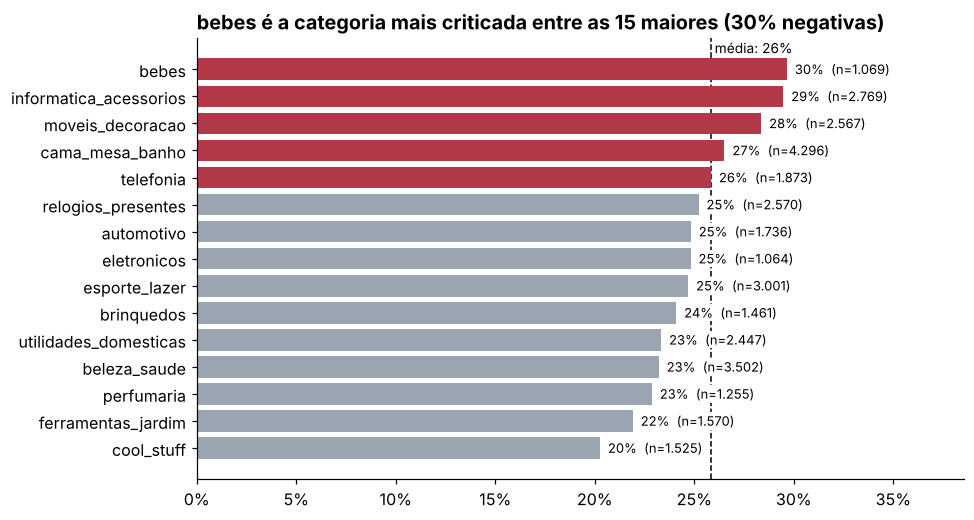

Fora do ranking, sem_categoria: 1.114 avaliações, 58% negativas; 45% são pedidos sem nenhum item; status: {'delivered': 576, 'unavailable': 409, 'canceled': 98}


In [10]:
cat = (completo.groupby("categoria")
       .agg(n=("review_id", "size"), negativas=("sentimento", lambda s: (s == "negativo").mean()),
            nota_media=("review_score", "mean")))
# "sem_categoria" não é uma categoria: reúne produtos sem categoria e pedidos sem nenhum item
# (cancelados ou indisponíveis), por isso fica fora do ranking
sem_cat = completo[completo["categoria"] == "sem_categoria"]
top = cat.drop(index="sem_categoria", errors="ignore").nlargest(15, "n").sort_values("negativas")
media_geral = (completo["sentimento"] == "negativo").mean()

fig, ax = plt.subplots(figsize=(9, 5.2))
cores = [NEGATIVO if v > media_geral else CINZA for v in top["negativas"]]
ax.barh(top.index, top["negativas"], color=cores)
ax.axvline(media_geral, color="black", lw=1, ls="--", zorder=0)
ax.text(media_geral, len(top) - 0.4, f" média: {pct(media_geral)}", fontsize=9)
for i, (v, n) in enumerate(zip(top["negativas"], top["n"])):
    ax.text(v + 0.004, i, f"{pct(v)}  (n={num(n)})", va="center", fontsize=8.5,
            bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
ax.xaxis.set_major_formatter(lambda v, _: pct(v))
ax.set_xlim(0, top["negativas"].max() * 1.3)
ax.set_title(f"{top.index[-1]} é a categoria mais criticada entre as 15 maiores "
             f"({pct(top['negativas'].iloc[-1])} negativas)")
salvar(fig, "08_categorias")
plt.show()
print(f"Fora do ranking, sem_categoria: {num(len(sem_cat))} avaliações, "
      f"{pct((sem_cat['sentimento'] == 'negativo').mean())} negativas; "
      f"{pct(sem_cat['n_itens'].isna().mean())} são pedidos sem nenhum item; "
      f"status: {sem_cat['order_status'].value_counts().head(3).to_dict()}")

**O que encontramos.** A insatisfação varia entre categorias com volume parecido. As categorias em
vermelho ficam acima da média geral de avaliações negativas. O grupo `sem_categoria`, fora do
ranking, é o mais negativo da base: boa parte dele são pedidos sem nenhum item, cancelados ou
indisponíveis, ou seja, compras que não aconteceram.

**Decisão.** `categoria` entra como metadado filtrável, para perguntas como "o que reclamam de
cama, mesa e banho?". O `resumo_categorias.parquet` traz esses números prontos para respostas agregadas.

## 9. Sobre o que os clientes falam?

Temas da T08 (`src/medallion/temas.py`). Uma avaliação pode citar mais de um tema; o gráfico da
esquerda conta todas as citações.

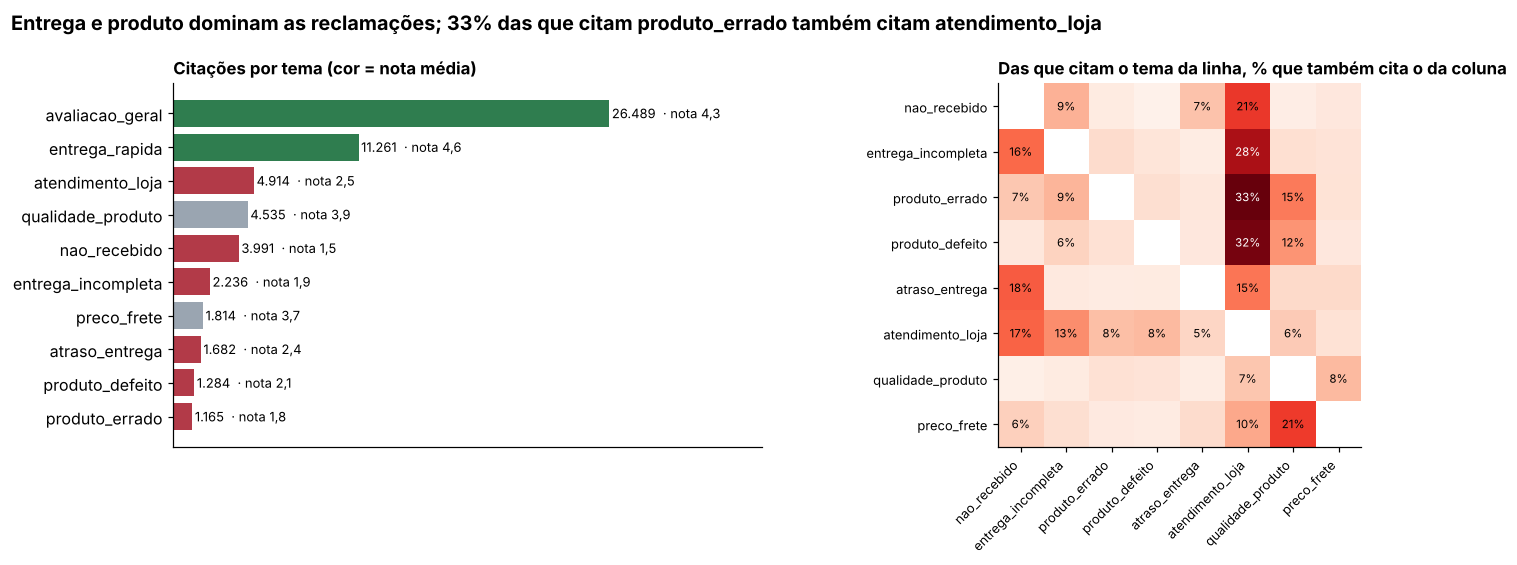

,citacoes,nota_media
t,,
avaliacao_geral,26489,4.31
entrega_rapida,11261,4.62
atendimento_loja,4914,2.45
qualidade_produto,4535,3.89
nao_recebido,3991,1.50
entrega_incompleta,2236,1.86
preco_frete,1814,3.69
atraso_entrega,1682,2.39
produto_defeito,1284,2.10


In [11]:
from src.medallion.temas import TEMAS

listas = completo["temas"].fillna("").str.split("|").map(lambda l: [t for t in l if t])
explodido = completo.assign(t=listas).explode("t").dropna(subset=["t"])
por_tema = (explodido.groupby("t")
            .agg(citacoes=("review_id", "size"), nota_media=("review_score", "mean"))
            .sort_values("citacoes"))

problemas = ["nao_recebido", "entrega_incompleta", "produto_errado", "produto_defeito",
             "atraso_entrega", "atendimento_loja", "qualidade_produto", "preco_frete"]
presenca = pd.DataFrame({t: listas.map(lambda l, t=t: t in l) for t in problemas})
# P(coluna | linha): das avaliações que citam o tema da linha, quantas também citam o da coluna
matriz = np.array([[presenca.loc[presenca[a], b].mean() for b in problemas] for a in problemas])
np.fill_diagonal(matriz, np.nan)
coocorrencia = pd.DataFrame(matriz, index=problemas, columns=problemas)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 1.15]})
cores = [NEGATIVO if v < 3 else (CINZA if v < 4 else POSITIVO) for v in por_tema["nota_media"]]
a1.barh(por_tema.index, por_tema["citacoes"], color=cores)
for i, (n, nota) in enumerate(zip(por_tema["citacoes"], por_tema["nota_media"])):
    a1.text(n + 150, i, f"{num(n)}  · nota {dec(nota)}", va="center", fontsize=8.5)
a1.set_xlim(0, por_tema["citacoes"].max() * 1.35)
a1.set_xticks([])
a1.set_title("Citações por tema (cor = nota média)", fontsize=11)

im = a2.imshow(coocorrencia.values, cmap="Reds", vmin=0, vmax=np.nanmax(coocorrencia.values))
a2.set_xticks(range(len(problemas)), problemas, rotation=45, ha="right", fontsize=8.5)
a2.set_yticks(range(len(problemas)), problemas, fontsize=8.5)
for i in range(len(problemas)):
    for j in range(len(problemas)):
        v = coocorrencia.values[i, j]
        if not np.isnan(v) and v >= 0.05:
            a2.text(j, i, pct(v), ha="center", va="center", fontsize=7.5,
                    color="white" if v > 0.25 else "black")
a2.set_title("Das que citam o tema da linha, % que também cita o da coluna", fontsize=11)

par = coocorrencia.stack().idxmax()
fig.suptitle(f"Entrega e produto dominam as reclamações; {pct(coocorrencia.loc[par])} das que citam "
             f"{par[0]} também citam {par[1]}", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
salvar(fig, "09_temas")
plt.show()
por_tema.sort_values("citacoes", ascending=False).assign(nota_media=lambda d: d["nota_media"].round(2))

**O que encontramos.** Os temas de problema têm notas médias muito mais baixas que os de elogio, e
eles aparecem juntos: quem reclama de um produto que não chegou ou veio errado muitas vezes também
reclama do atendimento da loja ao tentar resolver.

**Decisão.** O `tema` principal entra como metadado filtrável (T08), e a lista completa de temas fica
em `reviews_completo.parquet` para respostas agregadas com contagens (T24). Como os temas se
sobrepõem, as contagens por tema não somam 100%.

## 10. Que expressões separam elogio de reclamação?

Pares de palavras (bigramas) mais característicos das avaliações negativas (nota 1–2) e positivas
(nota 4–5), com a mesma tokenização do BM25 (`src.index.tokenizar`). A medida é a razão de chances
logarítmica: quanto maior, mais típico daquele grupo.

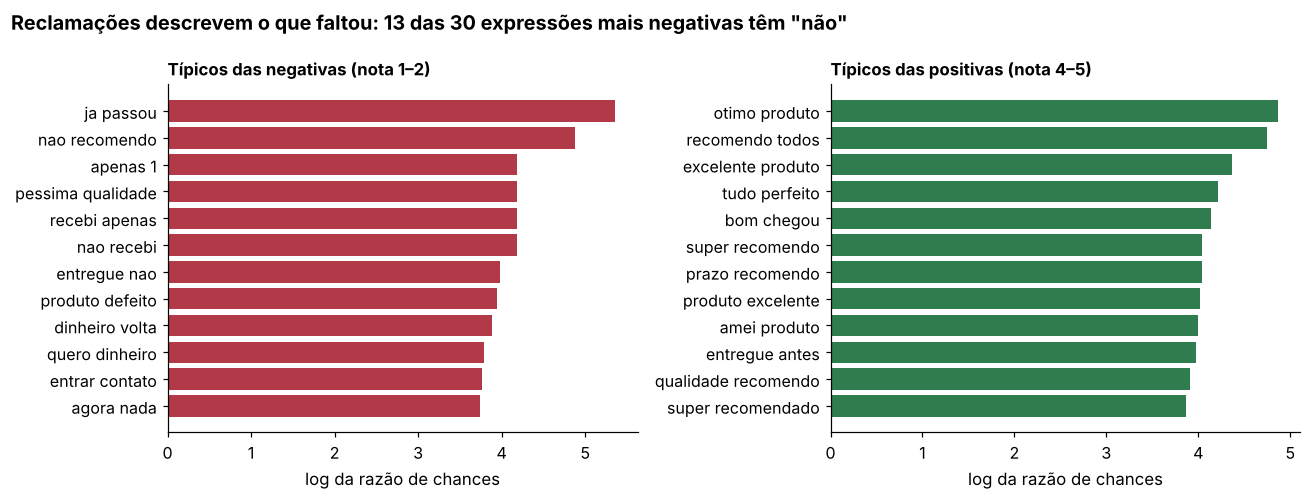

In [12]:
from src.index import tokenizar


def bigramas(texto):
    t = tokenizar(texto)
    return {" ".join(par) for par in zip(t, t[1:])}


grupos = {"negativa": completo[completo["review_score"] <= 2], "positiva": completo[completo["review_score"] >= 4]}
contagens = {g: Counter(b for txt in df["texto"] for b in bigramas(txt)) for g, df in grupos.items()}
n_doc = {g: len(df) for g, df in grupos.items()}
vocab = [b for b in set(contagens["negativa"]) | set(contagens["positiva"])
         if contagens["negativa"][b] + contagens["positiva"][b] >= 80]


def log_odds(b, a, c):
    pa = (contagens[a][b] + 1) / (n_doc[a] + 2)
    pc = (contagens[c][b] + 1) / (n_doc[c] + 2)
    return np.log(pa / (1 - pa)) - np.log(pc / (1 - pc))


tabela = pd.DataFrame({"bigrama": vocab})
tabela["log_odds_neg"] = [log_odds(b, "negativa", "positiva") for b in vocab]
tabela["% negativas"] = [contagens["negativa"][b] / n_doc["negativa"] for b in vocab]
tabela["% positivas"] = [contagens["positiva"][b] / n_doc["positiva"] for b in vocab]
neg = tabela.nlargest(12, "log_odds_neg").iloc[::-1]                      # maior no topo
pos = tabela.nsmallest(12, "log_odds_neg").assign(log_odds_neg=lambda d: -d["log_odds_neg"]).iloc[::-1]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6))
a1.barh(neg["bigrama"], neg["log_odds_neg"], color=NEGATIVO)
a1.set_title("Típicos das negativas (nota 1–2)", fontsize=11)
a2.barh(pos["bigrama"], pos["log_odds_neg"], color=POSITIVO)
a2.set_title("Típicos das positivas (nota 4–5)", fontsize=11)
for a in (a1, a2):
    a.set_xlabel("log da razão de chances")
neg_nao = [b for b in tabela.nlargest(30, "log_odds_neg")["bigrama"] if b.startswith("nao ") or " nao" in b]
fig.suptitle(f"Reclamações descrevem o que faltou: {len(neg_nao)} das 30 expressões mais negativas têm \"não\"",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
salvar(fig, "10_expressoes")
plt.show()

**O que encontramos.** As expressões típicas das reclamações descrevem o que deu errado: prazo
vencido ("já passou"), entrega parcial ("recebi apenas", "apenas 1"), dinheiro de volta e contato
com a loja. Uma boa parte delas traz negação ("não recebi", "não recomendo"). As dos elogios falam de
qualidade, prazo e recomendação.

**Decisão.** O BM25 (T06) remove palavras vazias, mas **mantém "não", "nem" e "nunca"**: sem elas,
"recebi" e "não recebi" seriam a mesma busca. Pelo mesmo motivo, as regras de temas (T08) tratam
negação explicitamente ("sem nenhum defeito" não é defeito).

## Conclusões

In [13]:
resumo = pd.DataFrame([
    ("1. Funil", f"Só {pct(funil['pct'].iloc[1])} das avaliações têm texto; {num(funil['n'].iloc[-1])} viram documentos.",
     "Só avaliações com texto entram no RAG."),
    ("2. Quem escreve", f"Negativas: {pct(neg_todas)} de todas, {pct(neg_texto)} das com texto.",
     "Proporções vêm das notas de todas as avaliações; o RAG cita a voz mais crítica."),
    ("3. Tamanho", f"Mediana de {tam.median():.0f} caracteres; formulário limitado a ~200.",
     "1 review = 1 chunk; remove textos sem conteúdo."),
    ("4. Repetidos", f"{num(qualidade['removidas_texto_identico'])} cópias de textos idênticos.",
     "Uma cópia por texto no índice; contagens em reviews_completo."),
    ("5. Tempo", f"Compras de {mensal_ok.index.min()} a {mensal_ok.index.max()}; negativas acompanham "
     f"o atraso mês a mês (r = {dec(r_mes, 2)}).",
     "Filtros de período (ano_mes); avisar quando houver pouca evidência."),
    ("6. Atraso", f"Negativas: {pct(neg_prazo)} no prazo, {pct(neg_atraso)} com atraso, {pct(neg_nao_entregue)} sem entrega.",
     "dias_atraso e atrasou como metadados; temas atraso_entrega e nao_recebido."),
    ("7. Estados", f"Correlação atraso × nota entre estados: r = {dec(r, 2)}.", "estado como metadado filtrável."),
    ("8. Categorias", f"Mais criticada entre as 15 maiores: {top.index[-1]} ({pct(top['negativas'].iloc[-1])}).",
     "categoria como metadado; resumo_categorias."),
    ("9. Temas", "Problemas de entrega e produto dominam e aparecem juntos.", "tema como metadado; contagens por tema (T24)."),
    ("10. Expressões", f"{len(neg_nao)} das 30 expressões mais negativas têm negação.", "BM25 mantém \"não\", \"nem\" e \"nunca\"."),
], columns=["Seção", "Achado", "Decisão no pipeline"])
resumo.style.hide(axis="index").set_properties(**{"text-align": "left"})

Seção,Achado,Decisão no pipeline
1. Funil,Só 43% das avaliações têm texto; 34.912 viram documentos.,Só avaliações com texto entram no RAG.
2. Quem escreve,"Negativas: 15% de todas, 26% das com texto.",Proporções vêm das notas de todas as avaliações; o RAG cita a voz mais crítica.
3. Tamanho,Mediana de 54 caracteres; formulário limitado a ~200.,1 review = 1 chunk; remove textos sem conteúdo.
4. Repetidos,7.039 cópias de textos idênticos.,Uma cópia por texto no índice; contagens em reviews_completo.
5. Tempo,"Compras de 2016-10 a 2018-08; negativas acompanham o atraso mês a mês (r = 0,69).",Filtros de período (ano_mes); avisar quando houver pouca evidência.
6. Atraso,"Negativas: 18% no prazo, 73% com atraso, 85% sem entrega.",dias_atraso e atrasou como metadados; temas atraso_entrega e nao_recebido.
7. Estados,"Correlação atraso × nota entre estados: r = -0,79.",estado como metadado filtrável.
8. Categorias,Mais criticada entre as 15 maiores: bebes (30%).,categoria como metadado; resumo_categorias.
9. Temas,Problemas de entrega e produto dominam e aparecem juntos.,tema como metadado; contagens por tema (T24).
10. Expressões,13 das 30 expressões mais negativas têm negação.,"BM25 mantém ""não"", ""nem"" e ""nunca""."


**Limitações.** As notas e os textos são de clientes que quiseram avaliar, o que não representa todos
os compradores (seção 2). Os temas vêm de regras com cerca de 80% de acerto (T08). A data prometida
de entrega é a que a Olist mostrou ao cliente, não um prazo logístico real.